# Getting started with minigeo

minigeo describes simple 3D geometry in Python — points, lines, boxes, cylinders — and draws it
with matplotlib, as SVG, or interactively with plotly. This notebook walks through the main ideas:

1. geometries and transforms
2. a shape's own axes x', y', z'
3. anchors: named points, as in TikZ
4. scenes and styles, and the three backends

[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/asteppke/minigeo/HEAD?labpath=examples%2Fgetting_started.ipynb) [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/asteppke/minigeo/blob/main/examples/getting_started.ipynb)

In [1]:
# On Google Colab, install minigeo first (elsewhere this cell does nothing)
import sys

if "google.colab" in sys.modules:
    %pip install -q "minigeo[all] @ git+https://github.com/asteppke/minigeo"

In [2]:
import numpy as np

from minigeo import (
    Angle,
    Axis,
    Box,
    Circle,
    Cone,
    Cylinder,
    Dimension,
    Group,
    Line,
    Plane,
    Point,
    Polygon,
    Rectangle,
    Scene,
    Sphere,
    Style,
    Transform,
    Vector,
)

## 1. Geometries

Every geometry has vertices in world coordinates. Shapes are created at a position, with
their sizes as named arguments; round shapes take `segments=` for a finer or coarser look.

In [3]:
point = Point([1, 1, 1])
line = Line([0, 0, 0], [2, 1, 0])
axis = Axis(direction=[0, 0, 1], position=[1, 0, 0])
box = Box([0, 0, 0], size=[1, 2, 3])  # width (x), length (y), height (z)
cylinder = Cylinder([2, 0, 0], radius=0.5, height=2)  # stands on its position
cone = Cone([4, 0, 0], radius=0.5, height=1)  # pointed; top_radius=0.2 would cut it off
sphere = Sphere([6, 0, 0], radius=0.5, segments=24)
circle = Circle([0, 3, 0], radius=0.5)
rectangle = Rectangle([2, 3, 0], size=[1, 0.5])
triangle = Polygon([4, 3, 0], [[0, 0, 0], [1, 0, 0], [0, 1, 0]])  # corners relative to the position

for geometry in (point, line, axis, box, cylinder, cone, sphere):
    print(geometry)

Point at [1 1 1]
Line from [0 0 0] to [2 1 0]
Axis at [1. 0. 0.] with direction [0. 0. 1.]
Box at [0. 0. 0.] of size [1. 2. 3.]
Cylinder at [2. 0. 1.] with radius 0.5 and height 2.0
Cone at [4.  0.  0.5] with radius 0.5 (bottom), 0.0 (top) and height 1.0
Sphere at [6. 0. 0.] with radius 0.5


## 2. Transforms

A `Transform` is a 4×4 matrix built step by step. `transform @ shape` applies it to the shape
(in place) and returns the shape; `t1 @ t2` combines two transforms (`t2` first).

In [4]:
p = Point([1, 0, 0])
Transform().translate([0, 0, 2]) @ p
print("moved up:", p.position)

quarter_turn = Transform().rotate("z", 90)
print("turned:  ", (quarter_turn @ Point([1, 0, 0])).position.round(6))

move_then_turn = quarter_turn @ Transform().translate([1, 0, 0])
print("combined:", (move_then_turn @ Point([0, 0, 0])).position.round(6))

moved up: [1. 0. 2.]
turned:   [0. 1. 0.]
combined: [0. 1. 0.]


Rotations turn around an axis through the origin. With `about=` the axis passes through
another point instead, for example the shape's own center:

In [5]:
box = Box([5, 0, 0], size=[2, 1, 1])
box.rotate("z", 90)
print("around the origin:", box.center.round(6))

box = Box([5, 0, 0], size=[2, 1, 1])
box.rotate("z", 90, about="center")
print("around its center:", box.center.round(6))

around the origin: [0. 5. 0.]
around its center: [5. 0. 0.]


## 3. A shape's own axes

Every shape has its own axes x', y', z'. They start aligned with x, y, z and turn with the
shape. Rotations can use them by name, e.g. `"x'"`:

In [6]:
box = Box([0, 0, 0], size=[2, 1, 0.5])
box.rotate("z", 60, about="center")
box.rotate("x'", 35, about="center")  # tilt around the box's own long axis
print(box.axes.round(3))  # rows: x', y', z' in world coordinates

[[ 0.5    0.866  0.   ]
 [-0.709  0.41   0.574]
 [ 0.497 -0.287  0.819]]


`frame=True` draws a shape's own axes as arrows (x′ red, y′ green, z′ blue), and
`scene.add_frame()` the world axes. Frames are looked up when the scene is drawn, so they turn
with the shape. A scene on the last line of a cell shows itself as an SVG drawing:

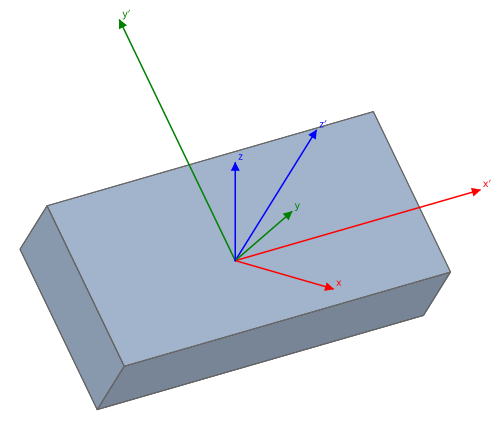

In [7]:
scene = Scene()
scene.add(box, fill="lightsteelblue", frame=True)
scene.add_frame(length=0.6)  # the world axes x, y, z at the origin, for comparison
scene

## 4. Anchors

Anchors are named points on a geometry, as in TikZ. For shapes and groups they combine
left/right (x'), front/back (y') and bottom/top (z'); lines use `start`, `midway`, `end`,
`near start` and `near end`. Anchors move and turn with the geometry.

`place(anchor, at=point)` moves a geometry so that one of its anchors sits on a point:

In [8]:
table = Box([0, 0, 0], size=[2, 1, 0.1], anchor="bottom")
print("top of the table:     ", table.anchor("top"))
print("a corner:             ", table.anchor("top front left"))

book = Box([0, 0, 0], size=[0.5, 0.35, 0.06])
book.rotate("z'", 20, about="center")
book.place("bottom", at=table.anchor("top"))
print("book lies on the table:", book.anchor("bottom"))

edge = Line(table.anchor("top front left"), table.anchor("top front right"))
print("three quarters along: ", edge.anchor("near end"))

top of the table:      [0.  0.  0.1]
a corner:              [-1.  -0.5  0.1]
book lies on the table: [0.  0.  0.1]
three quarters along:  [ 0.5 -0.5  0.1]


## 5. Scenes and styles

Geometry does not know how it is drawn. A `Scene` collects geometries with their `Style`
(fill, stroke, opacity, line width, dashes, arrows, labels). `scene.add` returns the
geometry, so creating and adding fit on one line. Styles combine with `|`.

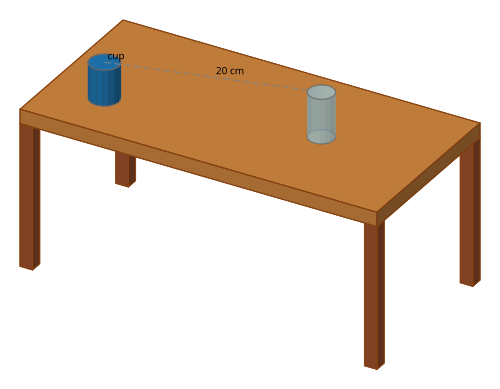

In [9]:
wood = Style(fill="peru", stroke="saddlebrown")

scene = Scene()
table = scene.add(Box([0, 0, 0.8], size=[2, 1, 0.08], anchor="bottom"), wood)
for corner in ("front left", "front right", "back left", "back right"):
    leg = Box(table.anchor(f"bottom {corner}"), size=[0.07, 0.07, 0.8], anchor=f"top {corner}")
    scene.add(leg, wood | Style(fill="sienna"))

cup = scene.add(Cylinder(table.anchor("top front left") + [0.3, 0.3, 0], radius=0.08, height=0.2), fill="C0")
scene.label(cup, "cup", at="top")
glass = scene.add(Cylinder(table.anchor("top") + [0.4, 0, 0], radius=0.07, height=0.25), fill="lightblue", opacity=0.5)
scene.add(Line(cup.anchor("top"), glass.anchor("top")), stroke="gray", dash="dashed", label="20 cm", label_at="midway")
scene

### The same scene with the three backends

* **SVG** (above, and `scene.render("svg")`): a vector drawing like a TikZ picture; `.save("scene.svg")`.
* **matplotlib**: a 3D axes you can combine with other plots; the view can be rotated in interactive backends.
* **plotly**: interactive in the browser and in Jupyter; `.write_html("scene.html")` saves it.

All three take the same view options: `elev`, `azim` and `vertical_axis`.

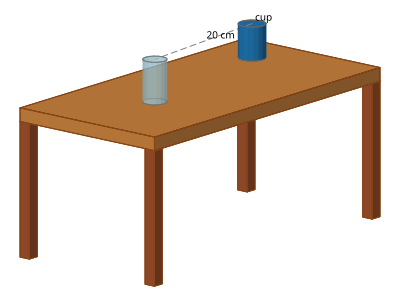

In [10]:
scene.render("svg", elev=15, azim=40, width=400)

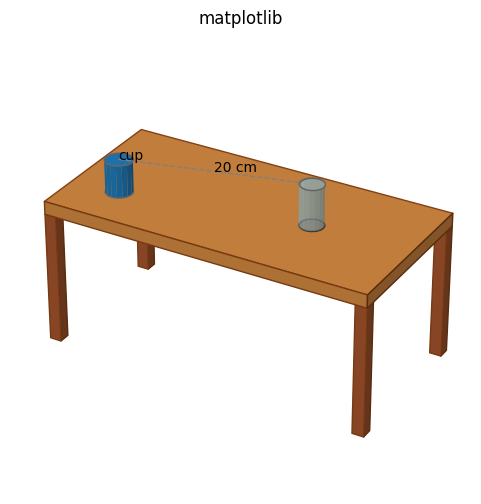

In [11]:
import matplotlib.pyplot as plt

ax = scene.render("matplotlib", show_axes=False)
ax.set_title("matplotlib")
plt.show()

In [ ]:
scene.render("plotly", height=400)

## 6. Understanding a transform

Seeing a shape before and after a transform helps to understand it. The original box is drawn
transparent, the rotated copy solid, and the rotation axis as an arrow.

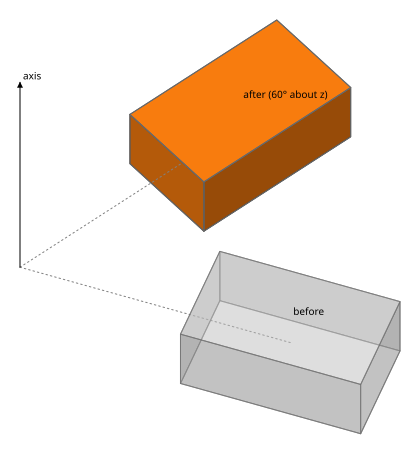

In [13]:
before = Box([1.5, 0, 0], size=[1, 0.6, 0.4])
after = before.copy()  # an independent copy, so `before` stays where it is
rotation_axis = np.array([0, 0, 1])
after.rotate(rotation_axis, 60, about=[0, 0, 0])

scene = Scene()
scene.add(before, fill="lightgray", opacity=0.4, label="before", label_at="top")
scene.add(after, fill="C1", label="after (60° about z)", label_at="top")
scene.add(Axis(rotation_axis, length=1.5), stroke="black", label="axis", label_at="end")
scene.add(Line([0, 0, 0], before.center), stroke="gray", dash="dotted")
scene.add(Line([0, 0, 0], after.center), stroke="gray", dash="dotted")
scene.render("svg", elev=50, azim=-70, width=420)

A sequence of small pictures shows how a rotation develops — here a box turning about its
own tilted axis, step by step:

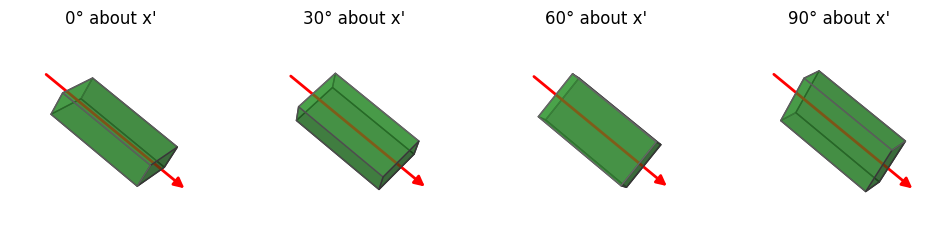

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3), subplot_kw={"projection": "3d"})
box = Box([0, 0, 0], size=[1.2, 0.6, 0.3])
box.rotate("y", 30, about="center")
for step, ax in enumerate(axes):
    scene = Scene()
    scene.add(box, fill="C2", opacity=0.6)  # translucent, so the axis shows through
    scene.add(Axis(box.axes[0], position=box.center - box.axes[0], length=2), stroke="red", line_width=2)
    scene.render("matplotlib", ax=ax, show_axes=False, elev=20, azim=-60)
    ax.set_title(f"{30 * step}° about x'")
    box.rotate("x'", 30, about="center")
plt.show()

## 7. Vectors, planes, angles and dimensions

A `Vector` is an arrow that also does vector algebra: `+`, `-`, scaling, `dot`, `cross`,
`angle_to` and `projected_onto`. Results start at the first vector's origin, so they can be
drawn right away. `Angle` draws the arc between two rays (a right angle gets a square), and
labels of vectors and angles go to sensible places by default.

a · b = 1.68,  angle = 60.9°


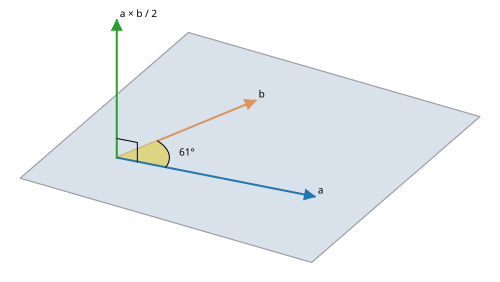

In [15]:
a = Vector([2, 0.3, 0])
b = Vector([0.6, 1.6, 0])
print(f"a · b = {a.dot(b):.2f},  angle = {a.angle_to(b):.1f}°")

scene = Scene()
scene.add(Plane([1, 0.8, 0], normal=[0, 0, 1], size=3.2), fill="lightsteelblue")
scene.add(a, stroke="C0", line_width=2, label="a")
scene.add(b, stroke="C1", line_width=2, label="b")
scene.add(a.cross(b) / 2, stroke="C2", line_width=2, label="a × b / 2")
scene.add(Angle.between(a, b, radius=0.5), fill="khaki", label=f"{a.angle_to(b):.0f}°")
scene.add(Angle.between(a, a.cross(b), radius=0.3))  # a right angle
scene

A `Plane` is drawn as a translucent patch. It knows distances, projections and intersections —
here a point is projected onto the ground plane, and a `Dimension` shows its height.

height above the plane: 1.2


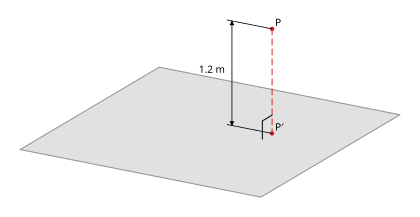

In [16]:
ground = Plane([0, 0, 0], normal=[0, 0, 1], size=3)
p = np.array([0.6, 0.3, 1.2])
foot = ground.project(p)
print("height above the plane:", ground.distance_to(p))

scene = Scene()
scene.add(ground, fill="lightgray")
scene.add(Point(p), fill="C3", label="P")
scene.add(Point(foot), fill="C3", label="P′")
scene.add(Line(p, foot), stroke="C3", dash="dashed")
scene.add(Angle(foot, p, foot + [0, -1, 0], radius=0.3))
scene.add(Dimension(foot, p, offset=[-0.5, 0, 0], unit=" m"))
scene.render("svg", elev=20, width=420)

Dimension lines work on any two points, for example the edges of a box:

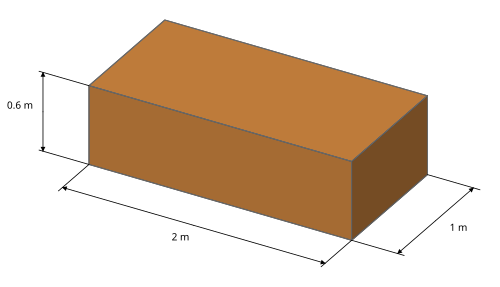

In [17]:
box = Box([0, 0, 0], size=(2, 1, 0.6), anchor="bottom")
scene = Scene()
scene.add(box, fill="peru")
scene.add(Dimension(box.anchor("bottom front left"), box.anchor("bottom front right"), offset=[0, -0.35, 0], unit=" m"))
scene.add(Dimension(box.anchor("bottom front right"), box.anchor("bottom back right"), offset=[0.35, 0, 0], unit=" m"))
scene.add(Dimension(box.anchor("bottom front left"), box.anchor("top front left"), offset=[-0.35, 0, 0], unit=" m"))
scene